<a href="https://colab.research.google.com/github/log-s-l/Energy-Consumption-Forecasting-ML-Model/blob/main/Copy_of_hw1_PCA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CS171/EE142 — Fall 2026
## Programming Assignment 1: Principal Component Analysis (PCA) & K-means Clustering

**Due:** November 8, 2026 @ 11:59pm PT

**Submission:** Upload a **PDF** of your completed notebook to [**Gradescope**](https://www.gradescope.com/courses/1438128), and assign pages to every question. Make sure every cell has been run, so that all plots and printed numbers are visible in the PDF. See the *Programming Assignment Guidelines* for how to export a PDF from Jupyter or Colab.

**Maximum points:** 10 total: **8 points for this coding assignment** (including written responses) + **2 points for the Canvas quiz**.

| Component | Points |
|---|---:|
| Question 1: PCA | 4.5 |
| Question 2: K-means | 3.5 |
| Canvas timed quiz | 2 |
| **Total** | **10** |

> **Canvas quiz reminder (2 points):** Complete this assignment **before** starting the quiz on Canvas. The quiz is timed (**5 minutes**) and allows **one attempt only**. Start it only after you have finished the notebook and reviewed your results.

<div style="margin-bottom: 15px; padding: 15px; color: #31708f; background-color: #d9edf7; border: 1px solid #bce8f1; border-radius: 5px;">
    
<b><font size=+2>Enter your information below:</font></b></br></br>

  <b>(full) Name</b>: Logan Lee
  </br>

  <b>Student ID Number</b>:  862422073
  </br></br>
    
<b>By submitting this notebook, I assert that the work below is my own work, completed for this course.  Except where explicitly cited, none of the portions of this notebook are duplicated from anyone else's work or my own previous work.</b>
</div>

<div style="padding: 15px; color: #8a6d3b; background-color: #fcf8e3; border: 1px solid #faebcc; border-radius: 5px;">
<b><font size=+2>Academic Integrity</font></b></br>
Each assignment should be done  individually. You may discuss general approaches with other students in the class, and ask questions to the TA, but  you must only submit work that is yours . If you receive help by any external sources (other than the TA and the instructor), you must properly credit those sources. See the <a href="https://conduct.ucr.edu/policies/academic-integrity-policies-and-procedures" target="_blank">UCR Academic Integrity policies</a>.
</div>

# Overview
In this assignment you will:
1. **Implement PCA from scratch** (Question 1) on a dataset of handwritten digits, and see how the reconstructed images change as you keep more or fewer principal components.
2. **Implement k-means clustering from scratch** (Question 2), run it on the PCA-reduced data, and check how well it groups the digits *without ever seeing the labels*.

**Rules**
* Use [NumPy](https://numpy.org/) and [Matplotlib](https://matplotlib.org/) for your implementations. `scikit-learn` is used **only to load the dataset**.
* You **may** use `np.linalg` for matrix decompositions (e.g., `np.linalg.eigh`, `np.linalg.svd`).
* You may **not** use ready-made implementations such as `sklearn.decomposition.PCA` or `sklearn.cluster.KMeans`; using them gives 0 points for that part. When in doubt, **just ask** the TA.

**How to work through this notebook**
* Replace every `None  # YOUR CODE HERE` with your code, and fill in every **[YOUR ANSWER HERE]** cell.
* Do **not** rename functions or change their arguments.
* Run the cells **from top to bottom**. Many code cells end with a **sanity check**. If one raises an `AssertionError`, fix that step before moving on, since later steps build on it. (Passing a check does not guarantee full credit, but failing one means something is wrong.)
* Before submitting: restart and run all cells (Colab: *Runtime → Restart session and run all*; Jupyter: *Kernel → Restart Kernel and Run All Cells*), check that there are no errors, then export to PDF.

In [ ]:
# If you get "ModuleNotFoundError", uncomment the next line, run this cell once, then restart the kernel.
# %pip install numpy matplotlib scikit-learn

%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits  # used ONLY to load the data

np.random.seed(42)  # for reproducible results -- do not change

## Question 1: PCA [4.5 points]

### Background: PCA in six steps
We store the data as a matrix $X \in \mathbb{R}^{n \times d}$ with **one image per row** ($n$ images, $d$ pixels each).

| Step | What you compute | Shape |
|---|---|---|
| 1. Standardize | $Z = (X - \mu) / \sigma$, column by column | $n \times d$ |
| 2. Covariance matrix | $C = \frac{1}{n-1} Z^\top Z$ | $d \times d$ |
| 3. Eigendecomposition | $C = V \Lambda V^\top$ (eigenvalues $\lambda_1, \dots, \lambda_d$; eigenvectors = **columns** of $V$) | $d$ and $d \times d$ |
| 4. Sort | order eigenvalues from largest to smallest, and reorder the eigenvector columns the same way | |
| 5. Keep the top $k$ | $W = V_{:,\,1:k}$ (the first $k$ columns) | $d \times k$ |
| 6. Project, then reconstruct | $P = Z W$, &nbsp; $\hat{Z} = P W^\top$ | $n \times k$, &nbsp; $n \times d$ |

**Intuition:** each eigenvector is a direction in pixel space, and its eigenvalue $\lambda_i$ is how much the data varies along that direction. Keeping only the top $k$ directions keeps most of the information with far fewer numbers per image.

### The dataset
We use scikit-learn's [**digits** dataset](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html), a small MNIST-like dataset of **1,797** grayscale images of handwritten digits 0–9. Each image is **8×8 pixels**, already flattened into a vector of **64** numbers with values from 0 (white) to 16 (black).

data shape:   (1797, 64)
labels shape: (1797,)


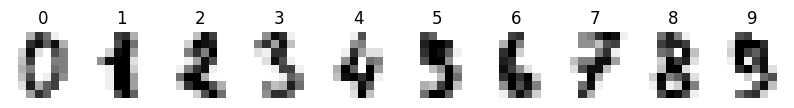

In [ ]:
digits = load_digits()
data = digits.data           # (1797, 64): one flattened 8x8 image per row
true_labels = digits.target  # (1797,):   the digit (0-9) shown in each image
IMAGE_SHAPE = (8, 8)

print("data shape:  ", data.shape)
print("labels shape:", true_labels.shape)

# Show one example of each digit
fig, axes = plt.subplots(1, 10, figsize=(10, 1.5))
for digit, ax in enumerate(axes):
    ax.imshow(data[true_labels == digit][0].reshape(IMAGE_SHAPE), cmap='gray_r', vmin=0, vmax=16)
    ax.set_title(digit)
    ax.axis('off')
plt.show()

### (a) [0.5 points] Standardize the data
Shift and scale every **column** (pixel) so it has mean 0 and standard deviation 1:
$$z_{ij} = \frac{x_{ij} - \mu_j}{\sigma_j}$$

*Hints:* `np.mean(..., axis=0)` averages each column. NumPy broadcasting lets you subtract a `(64,)` vector from a `(1797, 64)` matrix directly. Some pixels (e.g., the corners) are always 0, so their $\sigma_j = 0$; that is why `1e-10` is added to `std`.

In [ ]:
def standardize(data):
    '''
    Standardize each column of the data to mean 0 and standard deviation 1.

    Args:
        data: (n, d) array, one sample per row.
    Returns:
        data_standardized: (n, d) array.
        mean: (d,) array, the mean of each column.
        std:  (d,) array, the standard deviation of each column.
    '''
    mean = np.mean(data, axis = 0)
    std = np.std(data, axis=0) + 1e-10  # 1e-10 avoids division by zero for constant pixels
    data_standardized = (data - mean) / std
    return data_standardized, mean, std


data_standardized, mean, std = standardize(data)
print("data_standardized:", data_standardized.shape)
print("mean:", mean.shape, "  std:", std.shape)

# Sanity checks
assert mean.shape == (64,), "mean should have one value per column (pixel). Did you use axis=0?"
assert np.allclose(data_standardized.mean(axis=0), 0), "Every column should now have mean 0."
assert np.allclose(data_standardized.std(axis=0)[std > 1e-6], 1), "Every non-constant column should now have std 1."

data_standardized: (1797, 64)
mean: (64,)   std: (64,)


### (b) [1 point] Covariance matrix, eigenvalues and eigenvectors

**Covariance matrix.** Compute $C = \frac{1}{n-1} Z^\top Z$ (since $Z$ already has mean 0). You may use `np.cov` directly for full credit; note that by default it treats each **row** as a variable, so you need `np.cov(Z, rowvar=False)`.

**Eigendecomposition.** Because $C$ is symmetric, use `np.linalg.eigh`. It always returns *real* eigenvalues, sorted from **smallest to largest** (`np.linalg.eig` may return complex numbers with tiny imaginary parts). You then need to reverse the order.

*Hints:* `np.argsort(x)[::-1]` gives the indices that sort `x` from largest to smallest. Eigenvectors are the **columns**, so reorder them with `eigenvectors[:, idx]`, not `eigenvectors[idx]`.

In [ ]:
def compute_covariance_matrix(data_standardized):
    '''
    Args:
        data_standardized: (n, d) standardized data.
    Returns:
        covariance_matrix: (d, d) array.
    '''
    covariance_matrix = np.cov(data_standardized, rowvar = False)
    return covariance_matrix


covariance_matrix = compute_covariance_matrix(data_standardized)
print("covariance_matrix:", covariance_matrix.shape)

# Sanity checks
assert covariance_matrix.shape == (64, 64), "Expected a (d, d) = (64, 64) matrix. Did you mix up rows and columns?"
assert np.allclose(covariance_matrix, covariance_matrix.T), "A covariance matrix must be symmetric."

covariance_matrix: (64, 64)


In [ ]:
def compute_eigen(covariance_matrix):
    '''
    Args:
        covariance_matrix: (d, d) array.
    Returns:
        eigenvalues:  (d,) array, sorted from LARGEST to SMALLEST.
        eigenvectors: (d, d) array; column i is the eigenvector of eigenvalues[i].
    '''
    eigenvalues, eigenvectors = np.linalg.eigh(covariance_matrix)

    # Sort from largest to smallest eigenvalue, and reorder the eigenvector COLUMNS the same way
    sorted_indices = np.argsort(eigenvalues)[::-1]
    eigenvalues = eigenvalues[sorted_indices]
    eigenvectors = eigenvectors[:, sorted_indices]
    return eigenvalues, eigenvectors


eigenvalues, eigenvectors = compute_eigen(covariance_matrix)
print("eigenvalues:", eigenvalues.shape, "  eigenvectors:", eigenvectors.shape)
print("top 5 eigenvalues:", np.round(eigenvalues[:5], 3))

# Sanity checks
assert np.isrealobj(eigenvalues), "Eigenvalues should be real numbers. Use np.linalg.eigh for symmetric matrices."
assert np.all(np.diff(eigenvalues) <= 1e-10), "Eigenvalues should be sorted from largest to smallest."
assert np.allclose(covariance_matrix @ eigenvectors[:, 0], eigenvalues[0] * eigenvectors[:, 0]), \
    "Column 0 should be the eigenvector of the largest eigenvalue. Did you reorder the columns (not the rows)?"

eigenvalues: (64,)   eigenvectors: (64, 64)
top 5 eigenvalues: [7.345 5.835 5.154 3.966 2.966]


### (c) [1 point] How many components should we keep?
Each eigenvalue $\lambda_i$ is the variance captured by component $i$. The **fraction of variance explained** by the top $k$ components is
$$\text{explained}(k) = \frac{\lambda_1 + \dots + \lambda_k}{\lambda_1 + \dots + \lambda_d}.$$

1. In `plot_eigenvalue_analysis`, make two plots: (i) the eigenvalues $\lambda_i$ vs. $i$, and (ii) $\text{explained}(k)$ vs. $k$. Give every plot a **title and axis labels**. (Optional: you may also use AIC/BIC.)
2. In `find_optimal_k`, return the number of components $k$ you want to keep. A common rule is *the smallest $k$ that explains at least 90% or 95% of the variance*, but you may use another criterion as long as you justify it.
3. Explain your choice in the answer cell below.

*Hints:* `np.cumsum`, `np.argmax` on a boolean array (returns the index of the first `True`), `plt.subplots(1, 2, figsize=(12, 4))` for two side-by-side plots. Remember that Python indices start at 0 but $k$ starts at 1.

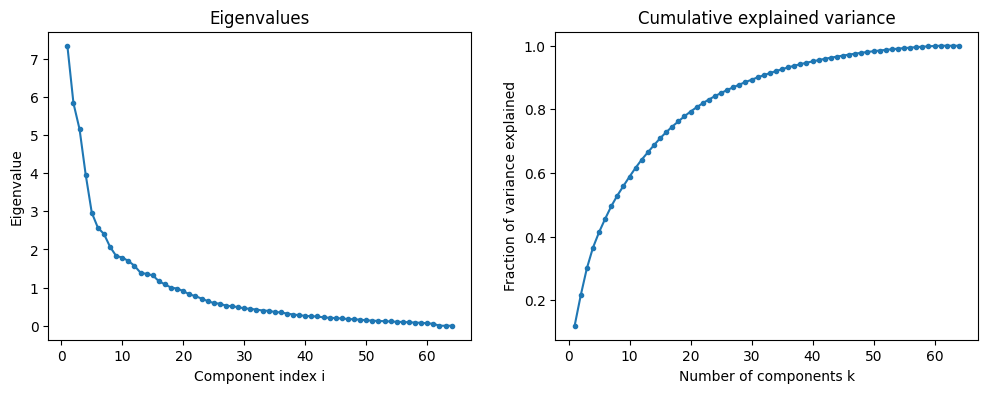

In [ ]:
def plot_eigenvalue_analysis(eigenvalues):
    '''Plot (i) the eigenvalues and (ii) the cumulative fraction of explained variance.'''
    k = np.arange(1, len(eigenvalues) + 1)                    # x axis values from 1-64
    explained = np.cumsum(eigenvalues) / np.sum(eigenvalues)  # fraction of total variance by top k components for every k at once

    fig, axes = plt.subplots(1, 2, figsize = (12, 4))

    axes[0].plot(k, eigenvalues, marker='o', markersize=3)
    axes[0].set_title("Eigenvalues")
    axes[0].set_xlabel("Component index i")
    axes[0].set_ylabel("Eigenvalue")

    axes[1].plot(k, explained, marker='o', markersize=3)
    axes[1].set_title("Cumulative explained variance")
    axes[1].set_xlabel("Number of components k")
    axes[1].set_ylabel("Fraction of variance explained")
    pass


plot_eigenvalue_analysis(eigenvalues)

In [ ]:
def find_optimal_k(eigenvalues):
    '''
    Args:
        eigenvalues: (d,) array, sorted from largest to smallest.
    Returns:
        k: int, the number of principal components to keep.
    '''

    explained = np.cumsum(eigenvalues) / np.sum(eigenvalues)
    k = int(np.argmax(explained >= 0.95)) + 1
    return k


n_components = find_optimal_k(eigenvalues)
print(f"Keeping k = {n_components} of {len(eigenvalues)} components")

Keeping k = 40 of 64 components


**Your answer (c):** [YOUR ANSWER HERE: which criterion/threshold did you use, which $k$ did you get, and why is it a reasonable choice? 2–3 sentences.]

I got k = 40, which means the smallest k that explains at least 95% of the variance is 40. This is reasonable because we can see the curve flattens out near k = 40, meaning that extra components add little. In other words, cutting the dimensions from 64 to 40 still preserves 95% of the variance.

### (d) [0.5 points] Project and reconstruct
Implement steps 5 and 6 from the table above:
* `project`: keep the first $k$ eigenvector columns, $W$ (shape $d \times k$), and compute $P = ZW$ (shape $n \times k$). Each image is now described by only $k$ numbers.
* `reconstruct`: map back to pixel space with $\hat{Z} = P W^\top$ (shape $n \times d$). This is the best approximation of $Z$ that uses only $k$ components.
* `restore_original_scale`: undo the standardization from (a), $\hat{X} = \hat{Z} \cdot \sigma + \mu$, so the reconstruction can be shown as an image.

The display function is provided.

In [ ]:
def project(data_standardized, eigenvectors, k):
    '''
    Project the data onto the top-k principal components.

    Args:
        data_standardized: (n, d) standardized data.
        eigenvectors: (d, d) sorted eigenvectors (columns).
        k: number of components to keep.
    Returns:
        data_projected: (n, k) array.
    '''
    W = eigenvectors[:, :k]  # YOUR CODE HERE: the first k eigenvector columns, shape (d, k)
    data_projected = data_standardized @ W  # YOUR CODE HERE
    return data_projected


def reconstruct(data_projected, eigenvectors):
    '''
    Map projected data back to the original (standardized) d-dimensional space.

    Args:
        data_projected: (n, k) array returned by project().
        eigenvectors: (d, d) sorted eigenvectors (columns).
    Returns:
        data_reconstructed: (n, d) array.
    '''
    k = data_projected.shape[1]
    W = eigenvectors[:, :k]
    data_reconstructed = data_projected @ W.T  # YOUR CODE HERE
    return data_reconstructed


def restore_original_scale(data_standardized, mean, std):
    '''Undo standardize(): map (n, d) standardized data back to the original pixel scale.'''
    data_restored = data_standardized * std + mean  # YOUR CODE HERE
    return data_restored


def show_original_vs_reconstructed(original, reconstructed, num_examples=6, seed=0):
    '''Show randomly chosen original images (top row) above their reconstructions (bottom row).'''
    rng = np.random.default_rng(seed)
    indices = rng.choice(len(original), size=num_examples, replace=False)
    fig, axes = plt.subplots(2, num_examples, figsize=(1.5 * num_examples, 3.2))
    for col, idx in enumerate(indices):
        axes[0, col].imshow(original[idx].reshape(IMAGE_SHAPE), cmap='gray_r', vmin=0, vmax=16)
        axes[1, col].imshow(reconstructed[idx].reshape(IMAGE_SHAPE), cmap='gray_r', vmin=0, vmax=16)
        axes[0, col].axis('off')
        axes[1, col].axis('off')
    axes[0, 0].set_title("Original", loc='left')
    axes[1, 0].set_title("Reconstructed", loc='left')
    plt.tight_layout()
    plt.show()

data_projected:     (1797, 40)
data_reconstructed: (1797, 64)


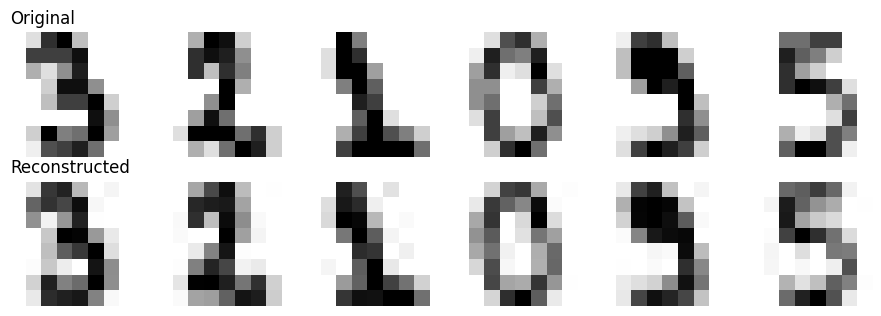

In [ ]:
data_projected = project(data_standardized, eigenvectors, n_components)
data_reconstructed = reconstruct(data_projected, eigenvectors)
print("data_projected:    ", data_projected.shape)
print("data_reconstructed:", data_reconstructed.shape)

# Sanity checks
assert data_projected.shape == (len(data), n_components)
assert np.allclose(reconstruct(project(data_standardized, eigenvectors, 64), eigenvectors), data_standardized), \
    "Keeping ALL 64 components should reconstruct the data exactly."
assert np.allclose(restore_original_scale(data_standardized, mean, std), data), \
    "restore_original_scale should exactly undo standardize."

show_original_vs_reconstructed(data, restore_original_scale(data_reconstructed, mean, std))

### (e) [0.5 points] Reconstruction error
Measure how far the reconstruction is from the original with the **mean squared error (MSE)**, averaged over all $n \times d$ entries:
$$\text{MSE} = \frac{1}{n\,d} \sum_{i=1}^{n} \sum_{j=1}^{d} \left(z_{ij} - \hat{z}_{ij}\right)^2$$

Compute it in the **standardized** space (compare $Z$ with $\hat{Z}$, not $X$ with $\hat{X}$). The mean has already been subtracted there, so it does not count toward the error, and every pixel is weighted equally.

The sanity check also compares your result with a known PCA fact: the reconstruction error equals the variance in the components you dropped, $\text{MSE} = \frac{n-1}{n\,d}\sum_{i>k} \lambda_i$.

In [ ]:
def compute_reconstruction_error(data_standardized, data_reconstructed):
    '''
    Args:
        data_standardized:  (n, d) original standardized data Z.
        data_reconstructed: (n, d) reconstruction Z_hat.
    Returns:
        error: float, the mean squared error.
    '''
    error = np.mean((data_standardized - data_reconstructed) ** 2)  # YOUR CODE HERE
    return error


reconstruction_error = compute_reconstruction_error(data_standardized, data_reconstructed)
print(f"k = {n_components}: reconstruction error (MSE) = {reconstruction_error:.4f}")

# Sanity check (theory: error = variance of the dropped components)
n, d = data_standardized.shape
expected_error = (n - 1) / (n * d) * eigenvalues[n_components:].sum()
assert np.isclose(reconstruction_error, expected_error), \
    f"Expected about {expected_error:.4f}. Average over ALL n*d entries, in the standardized space."

k = 40: reconstruction error (MSE) = 0.0469


### (f) [1 point] Effect of the number of components
Repeat the projection, reconstruction, and error computation for several values of $k$ (i.e., zero out different numbers of the smallest eigenvalues). Then:
1. Plot the MSE vs. $k$ (with title and axis labels).
2. Show what the reconstructed images look like for a few different $k$ (you can reuse `show_original_vs_reconstructed`).
3. Summarize your conclusions in the answer cell below.

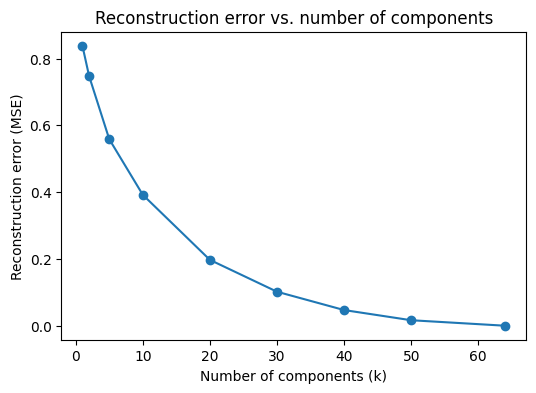

k = 1


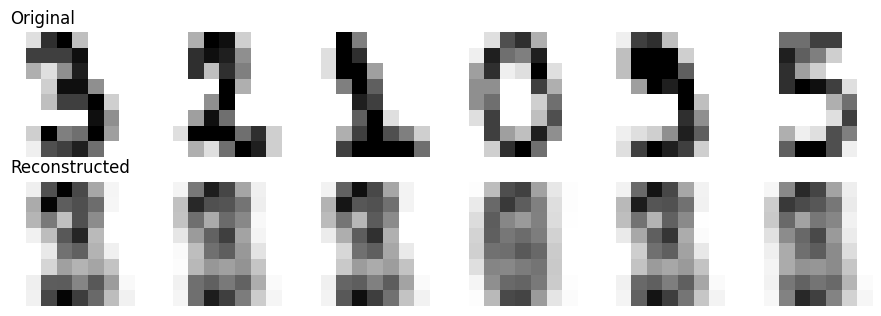

k = 5


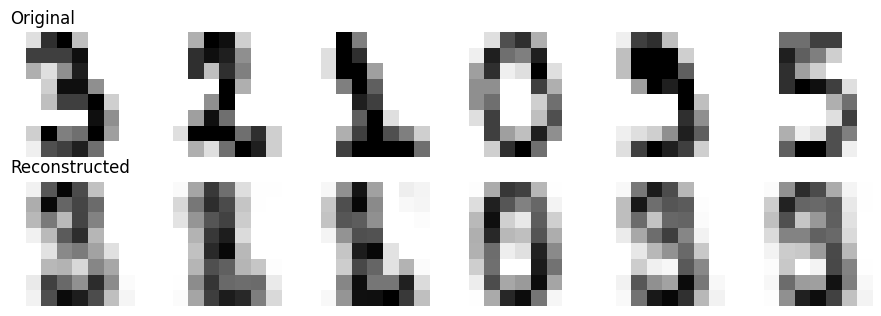

k = 10


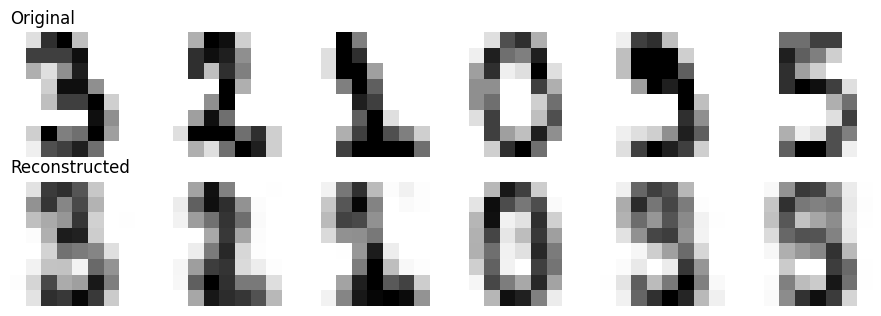

k = 20


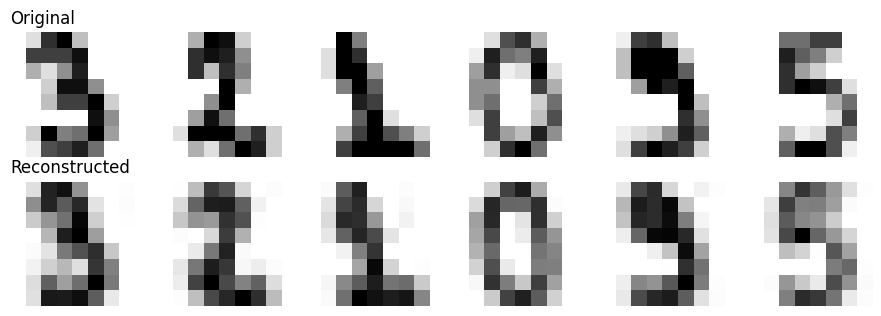

k = 40


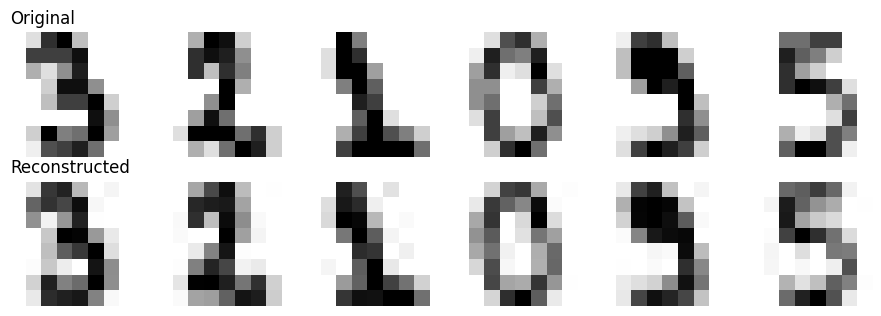

In [ ]:
ks = [1, 2, 5, 10, 20, 30, 40, 50, 64]
errors = []
for k in ks:
    # YOUR CODE HERE: project with k components, reconstruct, compute the MSE, append it to errors
    Z_projected = project(data_standardized, eigenvectors, k)
    Z_reconstructed = reconstruct(Z_projected, eigenvectors)
    errors.append(compute_reconstruction_error(data_standardized, Z_reconstructed))
    pass

# YOUR CODE HERE: plot errors vs. ks
plt.figure(figsize=(6, 4))
plt.plot(ks, errors, marker='o')
plt.title("Reconstruction error vs. number of components")
plt.xlabel("Number of components (k)")
plt.ylabel("Reconstruction error (MSE)")
plt.show()

# YOUR CODE HERE: show reconstructions for a few values of k
for k in [1, 5, 10, 20, 40]:
  Z_projected = project(data_standardized, eigenvectors, k)
  Z_reconstructed = reconstruct(Z_projected, eigenvectors)
  X_reconstructed = restore_original_scale(Z_reconstructed, mean, std) # Undo standardization so the images are on the 0-16 pixel scale
  print(f"k = {k}")
  show_original_vs_reconstructed(data, X_reconstructed)

**Your answer (f):** [YOUR ANSWER HERE: How does the error change as $k$ grows? How does this relate to the explained-variance plot from (c)? Roughly how many components are needed before the digits become easy to recognize? 3–5 sentences.]

Error decreases as k grows, falling quickly at first and then flattening, with diminishing returns. The MSE equals the variance of the dropped component, so it is essentially the mirror image of the cumulative explained variance curve, thus where that curve flattens, the error curve flattens to. Visually, around k=10, one might be reasonibly confident in recognizing the digits, and around k=20 one might be very confident.

## Question 2: K-means clustering on PCA-reduced data [3.5 points]

Now we group the images into clusters **without using the labels**, and then check how well the clusters match the real digits. We run k-means on the PCA-projected data from Question 1: fewer dimensions make it faster, and with 2 components we can plot the result.

### Background: the k-means algorithm
Given data points and a number of clusters $K$:
1. **Initialize:** pick $K$ different data points at random as the starting cluster centers (*centroids*).
2. **Assign:** give each point the label of its **nearest** centroid (Euclidean distance).
3. **Update:** move each centroid to the **mean** of the points assigned to it.
4. **Repeat** steps 2–3 until the centroids stop moving (or a maximum number of iterations is reached).

Note: we use **`n_clusters`** for the number of clusters $K$ and **`k`** for the number of PCA components. Don't mix them up!

In [ ]:
X_2d = project(data_standardized, eigenvectors, 2)  # keep the first 2 principal components
print("X_2d:", X_2d.shape)

X_2d: (1797, 2)


### (a) [2 points] Implement k-means from scratch
Do **not** use `scikit-learn` or any other library implementation of k-means.

*Hints:*
* Initialization: `rng.choice(n, size=n_clusters, replace=False)` picks distinct row indices.
* Assignment: the distances from every point to every centroid form an `(n, n_clusters)` matrix. Broadcasting helps: `X[:, None, :] - centroids[None, :, :]` has shape `(n, n_clusters, f)`. Then use `np.linalg.norm(..., axis=2)` and `np.argmin(..., axis=1)`.
* Update: `X[labels == j].mean(axis=0)` is the mean of cluster `j`. If a cluster ends up with no points, keep its old centroid (otherwise you get `nan`).

In [ ]:
def k_means(X, n_clusters, max_iter=300, seed=0):
    '''
    K-means clustering (Lloyd's algorithm).

    Args:
        X: (n, f) data, one point per row.
        n_clusters: number of clusters K.
        max_iter: maximum number of iterations.
        seed: random seed, so that the result is reproducible.
    Returns:
        labels:    (n,) int array, the cluster index (0 .. n_clusters-1) of each point.
        centroids: (n_clusters, f) array, the cluster centers.
    '''
    rng = np.random.default_rng(seed)

    # 1. Initialize: n_clusters DIFFERENT random rows of X
    n = X.shape[0] # n = number of data points
    centroids = X[rng.choice(n, size = n_clusters, replace = False)]  # YOUR CODE HERE

    for _ in range(max_iter):
        # 2. Assignment step: index of the nearest centroid for every point
        distances = np.linalg.norm(X[:, None, :] - centroids[None, :, :], axis = 2)
        labels = np.argmin(distances, axis = 1)  # YOUR CODE HERE

        # 3. Update step: mean of the points in each cluster (keep the old centroid if a cluster is empty)
        new_centroids = centroids.copy()  # YOUR CODE HERE
        for j in range(n_clusters):
          if np.any(labels == j): # only updates if cluster j has points
            new_centroids[j] = X[labels == j].mean(axis = 0)

        # 4. Stop when the centroids no longer move
        if np.allclose(centroids, new_centroids):
            break
        centroids = new_centroids

    return labels, centroids


N_CLUSTERS = 10  # one cluster per digit
cluster_labels, centroids = k_means(X_2d, N_CLUSTERS)
print("cluster_labels:", cluster_labels.shape, "  centroids:", centroids.shape)

# Sanity checks
assert cluster_labels.shape == (len(X_2d),)
assert centroids.shape == (N_CLUSTERS, 2)
assert set(np.unique(cluster_labels)) <= set(range(N_CLUSTERS)), "Labels must be integers 0 .. n_clusters-1."
assert not np.isnan(centroids).any(), "A centroid is nan. Did you handle empty clusters?"

cluster_labels: (1797,)   centroids: (10, 2)


Let's compare the true digits (left) with the k-means clusters (right) in the 2-D PCA space.

Note that **cluster numbers are arbitrary**: k-means never saw the labels, so "cluster 3" does not have to correspond to digit 3. Compare the *shapes* of the groups, not the colors.

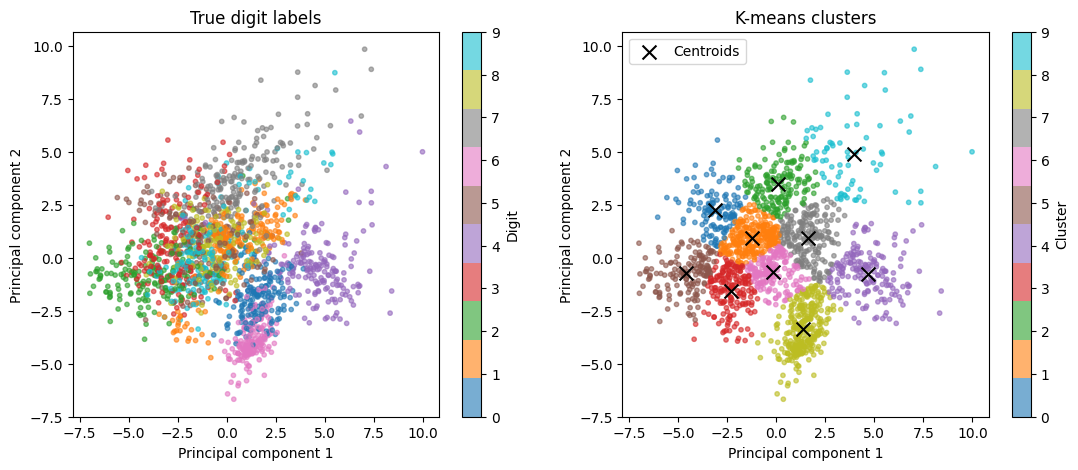

In [ ]:
def plot_clusters(X_2d, true_labels, cluster_labels, centroids):
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    panels = [(axes[0], true_labels, "True digit labels", "Digit"),
              (axes[1], cluster_labels, "K-means clusters", "Cluster")]
    for ax, labels, title, bar_label in panels:
        points = ax.scatter(X_2d[:, 0], X_2d[:, 1], c=labels, cmap='tab10', s=10, alpha=0.6)
        ax.set(title=title, xlabel='Principal component 1', ylabel='Principal component 2')
        fig.colorbar(points, ax=ax, ticks=range(10), label=bar_label)
    axes[1].scatter(centroids[:, 0], centroids[:, 1], c='black', marker='x', s=100, label='Centroids')
    axes[1].legend()
    plt.show()


plot_clusters(X_2d, true_labels, cluster_labels, centroids)

### (b) [1 point] Clustering accuracy per digit
Since cluster numbers are arbitrary, we first **name** each cluster after the digit that appears **most often** in it (a majority vote). Then we can compute accuracy as usual: an image counts as correct if its cluster's name equals its true digit.

1. In `analyze_clustering_accuracy`, find the most common digit in each cluster. *Hint:* `np.bincount(x)` counts how many times each integer appears in `x`, and `.argmax()` picks the most frequent one. The rest of the function is provided.
2. Try **several** numbers of PCA components for k-means (e.g., 2, 5, 10, and your $k$ from Q1), and set `n_components_kmeans` to the one you want to report.

In [ ]:
def analyze_clustering_accuracy(true_labels, cluster_labels):
    '''
    Name each cluster after its most common true digit, then measure accuracy.

    Args:
        true_labels:    (n,) true digit of each image.
        cluster_labels: (n,) cluster index of each image, from k_means().
    Returns:
        accuracy_per_digit: dict {digit: fraction of that digit's images that were labeled correctly}
        total_accuracy:     float, fraction of all images that were labeled correctly
        cluster_to_digit:   dict {cluster index: digit it was named after}
    '''
    cluster_to_digit = {}
    for cluster in np.unique(cluster_labels):
        digits_in_cluster = true_labels[cluster_labels == cluster]  # true digits of this cluster's members
        cluster_to_digit[cluster] = np.bincount(digits_in_cluster).argmax()  # YOUR CODE HERE: the most common digit in digits_in_cluster

    predicted_digits = np.array([cluster_to_digit[c] for c in cluster_labels])
    correct = (predicted_digits == true_labels)
    accuracy_per_digit = {digit: correct[true_labels == digit].mean() for digit in range(10)}
    total_accuracy = correct.mean()
    return accuracy_per_digit, total_accuracy, cluster_to_digit

In [ ]:
# TODO: try several values, then keep the one you want to report
n_components_kmeans = 10  # YOUR CODE HERE

X_reduced = project(data_standardized, eigenvectors, n_components_kmeans)
cluster_labels, centroids = k_means(X_reduced, N_CLUSTERS)
accuracy_per_digit, total_accuracy, cluster_to_digit = analyze_clustering_accuracy(true_labels, cluster_labels)

print(f"PCA components: {n_components_kmeans}   X_reduced: {X_reduced.shape}")
print(f"Overall accuracy: {total_accuracy:.4f}")
for digit, accuracy in accuracy_per_digit.items():
    print(f"  digit {digit}: {accuracy:.4f}")
print("cluster -> digit:", {int(c): int(d) for c, d in cluster_to_digit.items()})

PCA components: 10   X_reduced: (1797, 10)
Overall accuracy: 0.6483
  digit 0: 0.9775
  digit 1: 0.3132
  digit 2: 0.8870
  digit 3: 0.8197
  digit 4: 0.8729
  digit 5: 0.6813
  digit 6: 0.9890
  digit 7: 0.9274
  digit 8: 0.0000
  digit 9: 0.0000
cluster -> digit: {0: 3, 1: 5, 2: 7, 3: 1, 4: 4, 5: 2, 6: 2, 7: 0, 8: 6, 9: 7}


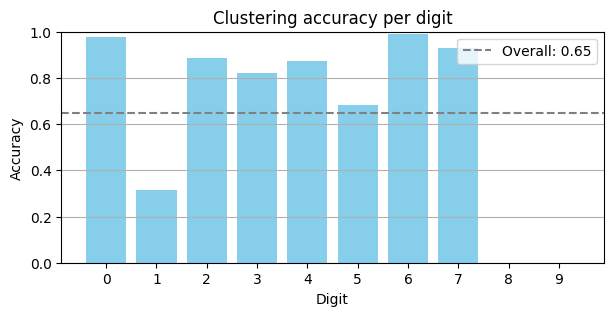

In [ ]:
def plot_accuracy_per_digit(accuracy_per_digit, total_accuracy):
    digits_ = list(accuracy_per_digit.keys())
    plt.figure(figsize=(7, 3))
    plt.bar(digits_, list(accuracy_per_digit.values()), color='skyblue')
    plt.axhline(total_accuracy, color='gray', linestyle='--', label=f'Overall: {total_accuracy:.2f}')
    plt.xlabel('Digit')
    plt.ylabel('Accuracy')
    plt.title('Clustering accuracy per digit')
    plt.xticks(digits_)
    plt.ylim(0, 1)
    plt.grid(axis='y')
    plt.legend()
    plt.show()


plot_accuracy_per_digit(accuracy_per_digit, total_accuracy)

### (c) [0.5 points] Summary
**Your answer (c):** [YOUR ANSWER HERE. Address, for example: Which digits are clustered well and which poorly, and why might that be (look at the 2-D plot)? How did the number of PCA components affect the accuracy? Was any digit not chosen as the name of any cluster (because two clusters were named after the same digit)? 3–5 sentences.]

I tried 5, 10, 25, and 50 PCA components and 25 gave the best overall accuracy (0.686). Accuracy rose from 0.597 with 5 components but did not improve at 50 (0.681). Digits 0, 4, and 6 clustered well in every run with at least 10 components (about 0.87-0.99), while digit 8 had 0.00 accuracy in every run. This is because digit 8 was never chosen as the name of any cluster: two clusters were always named after the same digit (2, and often 7), leaving some digit without one. In the 2-D plot, digits 0, 4, 6, and 7 form fairly distinct groups, which matches the high accuracy of 0, 4, and 6, while digits 1, 3, 5, 8, and 9 overlap heavily in the center, making it hard for k-means to separate them, so it splits or merges them across clusters.

---
### Before you submit
- [ ] Your name and student ID are filled in at the top.
- [ ] Restarting and running all cells finishes **without errors**, and all plots are visible.
- [ ] Every **[YOUR ANSWER HERE]** cell is answered.
- [ ] The PDF is uploaded to Gradescope, and every question has its pages assigned.

### After completing this assignment: Canvas quiz
The coding assignment is worth **8 points**, and the Canvas quiz is worth **2 points** (**10 points total**).

> **Complete this assignment before starting the quiz on Canvas.** The quiz has a **5-minute time limit** and allows **one attempt only**. Finish the notebook and review your results before you begin.

- [ ] After completing this assignment, complete the **5-minute Canvas quiz (one attempt only)**.
